In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [4]:
df = pd.read_csv("modelling (1).csv")

In [10]:
df['Open'].unique()

array([1])

## Feature Engineering

In the Rossman Sales dataset PromoInterval tells us which months recurring promotion (promo 2) is running.
If a store participates in Promo2 (meaning the Promo2 column is 1), it doesn't run the promotion every single day of the year. Instead, the promotion runs in a 3-month repeating cycle.

IsPromo2Active- tells the model whether a store's recurring promotion (Promo2) is active on a particular date.
-equals 1 when the store participates in Promo2, the programme has started, and the month is listed in PromoInterval. Otherwise, it equals 0.


In [5]:
df['Date'] = pd.to_datetime(df['Date'])

# Months in which the store starts a new Promo2 promotion
df['IsPromo2Active'] = df.apply(
    lambda row: int(
        row['Promo2'] == 1
        and pd.notna(row['PromoInterval'])
        and row['Date'].strftime('%b') in row['PromoInterval'].split(',')
        and row['Date'].isocalendar().year * 100
            + row['Date'].isocalendar().week
            >= row['Promo2SinceYear'] * 100
            + row['Promo2SinceWeek']
    ) if pd.notna(row['Promo2SinceYear'])
        and pd.notna(row['Promo2SinceWeek'])
        else 0,
    axis=1
)


In [6]:
df['IsPromo2Active'].unique()

array([0, 1])

Day 7 is adjacent to day 1 of the week (eg. monday is adjacent to sunday but the numbers make it seem like they are far apart)
So using sin/cos of month/dayofweek makes the month/dayofweek cyclic
sin and cos are used because for some values sin is 0 and for those values sin is not 0
This may imporve the performance of an mlp

In [7]:
# Day of week: 7-day cycle
df['DayOfWeek_sin'] = np.sin(2 * np.pi * df['DayOfWeek'] / 7)
df['DayOfWeek_cos'] = np.cos(2 * np.pi * df['DayOfWeek'] / 7)

# Month: 12-month cycle
df['Month_sin'] = np.sin(2 * np.pi * df['Month'] / 12)
df['Month_cos'] = np.cos(2 * np.pi * df['Month'] / 12)

In [8]:
# Remove open because all the stores we have in our final dataset is open

X = df[['DayOfWeek_sin',
    'DayOfWeek_cos',
    'Month_sin',
    'Month_cos',
    'Promo',
    'StateHoliday',
    'SchoolHoliday',
    'StoreType',
    'Assortment',
    'CompetitionDistance',
    'CompetitionOpenSinceMonth',
    'CompetitionOpenSinceYear',
    'Promo2',
    'Promo2SinceWeek',
    'Promo2SinceYear',
    'Year',
    'Month',
    'Day',
    'WeekOfYear',
    'IsPromo2Active',
    'Store']]
Y = df['Sales']



##Scaling/One-hot encoding


In [9]:

from sklearn.preprocessing import OneHotEncoder, StandardScaler
import pandas as pd

# 1. Create Date and sort chronologically
df = df.copy()
df['Date'] = pd.to_datetime(df[['Year', 'Month', 'Day']])
df = df.sort_values('Date').reset_index(drop=True)

# 2. Split by unique dates to prevent the same date
# from appearing in both train and test sets
dates = df['Date'].drop_duplicates().sort_values().to_numpy()
cutoff = dates[int(0.75 * len(dates))]

train_df = df[df['Date'] < cutoff].copy()
test_df = df[df['Date'] >= cutoff].copy()

print("Training period:", train_df['Date'].min(), "to", train_df['Date'].max())
print("Testing period:", test_df['Date'].min(), "to", test_df['Date'].max())
print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)

# 3. Define target and features
target_col = 'Sales'

categorical_cols = [
    'StateHoliday', 'StoreType', 'Assortment', 'Store'
]

numerical_cols = [
    'DayOfWeek_sin', 'DayOfWeek_cos',
    'Month_sin', 'Month_cos',
    'CompetitionDistance',
    'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear',
    'Promo2SinceWeek', 'Promo2SinceYear',
    'Year', 'Month', 'Day', 'WeekOfYear'
]

binary_cols = [
    'Open', 'Promo', 'SchoolHoliday',
    'Promo2', 'IsPromo2Active'
]

feature_cols = categorical_cols + numerical_cols + binary_cols

X_train = train_df[feature_cols].copy()
X_test = test_df[feature_cols].copy()

y_train = train_df[target_col].copy()
y_test = test_df[target_col].copy()

# 4. One-hot encode categorical variables
encoder = OneHotEncoder(
    handle_unknown='ignore',
    sparse_output=False
)

X_train_cat = pd.DataFrame(
    encoder.fit_transform(X_train[categorical_cols]),
    columns=encoder.get_feature_names_out(categorical_cols),
    index=X_train.index
)

X_test_cat = pd.DataFrame(
    encoder.transform(X_test[categorical_cols]),
    columns=encoder.get_feature_names_out(categorical_cols),
    index=X_test.index
)

# 5. Standardise numerical variables
scaler = StandardScaler()

X_train_num = pd.DataFrame(
    scaler.fit_transform(X_train[numerical_cols]),
    columns=numerical_cols,
    index=X_train.index
)

X_test_num = pd.DataFrame(
    scaler.transform(X_test[numerical_cols]),
    columns=numerical_cols,
    index=X_test.index
)

# 6. Keep binary variables unchanged
X_train_bin = X_train[binary_cols].copy()
X_test_bin = X_test[binary_cols].copy()

# 7. Combine processed features
X_train_processed = pd.concat(
    [X_train_num, X_train_cat, X_train_bin], axis=1
)

X_test_processed = pd.concat(
    [X_test_num, X_test_cat, X_test_bin], axis=1
)

# 8. Verify alignment and shapes
assert X_train_processed.columns.equals(X_test_processed.columns)
assert X_train_processed.index.equals(y_train.index)
assert X_test_processed.index.equals(y_test.index)

print("Processed train:", X_train_processed.shape)
print("Processed test:", X_test_processed.shape)
print("Cutoff date:", pd.Timestamp(cutoff))


Training period: 2013-01-01 00:00:00 to 2014-12-07 00:00:00
Testing period: 2014-12-08 00:00:00 to 2015-07-31 00:00:00
Train shape: (131225, 27)
Test shape: (43775, 27)
Processed train: (131225, 252)
Processed test: (43775, 252)
Cutoff date: 2014-12-08 00:00:00


In [10]:
from sklearn.metrics import (
    mean_absolute_error,
    root_mean_squared_error,
    r2_score
)

# Check for missing values
print("Missing values in training features:",
      X_train_processed.isna().sum().sum())

print("Missing values in test features:",
      X_test_processed.isna().sum().sum())

Missing values in training features: 0
Missing values in test features: 0


##MLP

In [11]:
from sklearn.neural_network import MLPRegressor

mlp = MLPRegressor(
 hidden_layer_sizes= (20,20),
 activation = 'relu',
 solver = 'adam',
 max_iter = 5000,
 early_stopping=True,
 random_state = 0,
 n_iter_no_change=20
)
mlp.fit(X_train_processed, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:698: UserWarning: Training interrupted by user.
  warnings.warn("Training interrupted by user.")


MLPRegressor(early_stopping=True, hidden_layer_sizes=(20, 20), max_iter=5000,
             n_iter_no_change=20, random_state=0)

In [12]:
Y_pred_test = mlp.predict(X_test_processed)
Y_pred_train = mlp.predict(X_train_processed)

In [13]:
# 2. Evaluate Training Set Metrics
train_mae = mean_absolute_error(y_train, Y_pred_train)
train_rmse = root_mean_squared_error(y_train, Y_pred_train)
train_r2 = r2_score(y_train,Y_pred_train)


# 3. Evaluate Testing Set Metrics
test_mae = mean_absolute_error(y_test, Y_pred_test)
test_rmse = root_mean_squared_error(y_test, Y_pred_test)
test_r2 = r2_score(y_test, Y_pred_test)

In [14]:
print("--- Training Metrics ---")
print(f"MAE : {train_mae}")
print(f"RMSE: {train_rmse}")
print(f"R2  : {train_r2}\n")

print("--- Testing Metrics ---")
print(f"MAE : {test_mae}")
print(f"RMSE: {test_rmse}")
print(f"R2  : {test_r2}")

--- Training Metrics ---
MAE : 1043.9088042494136
RMSE: 1478.5839772412621
R2  : 0.8356582360087859

--- Testing Metrics ---
MAE : 1249.8907165725454
RMSE: 1789.0166388183752
R2  : 0.7702199623719036


##Multivariate Linear Regression


In [18]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, root_mean_squared_error, mean_absolute_error

In [19]:
linear = LinearRegression()  # Instantatiate the linear regression model
linear.fit(X_train_processed,y_train)  # Fit the model parameters to the training data.

# Evaluate model performance.
training_predictions = linear.predict(X_train_processed)  # Get model predictions for both.
testing_predictions = linear.predict(X_test_processed)    # training and testing data.

# Create a table of the various scores.
results = pd.DataFrame({
    "R^2": {
        "train": r2_score(y_train, training_predictions),
        "test": r2_score(y_test, testing_predictions)
    },
    "RMSE": {
        "train": root_mean_squared_error(y_train, training_predictions),
        "test": root_mean_squared_error(y_test, testing_predictions)
    },
    "MAE": {
        "train": mean_absolute_error(y_train, training_predictions),
        "test": mean_absolute_error(y_test, testing_predictions)
    }
})

In [20]:
print(results)

            R^2         RMSE          MAE
train  0.711279  1959.798918  1426.550919
test   0.678394  2116.509262  1526.530965


In [24]:
feature_names = X_train_processed.columns.tolist() # write the column names to a list

# create a Series for which the rows are the feature names and the data is
# the regression coefficient values
coefficients = pd.Series(data=linear.coef_.transpose(), index=feature_names)
print(coefficients)

DayOfWeek_sin           168.954208
DayOfWeek_cos           572.794425
Month_sin               826.873603
Month_cos                34.871580
CompetitionDistance    -617.243797
                          ...     
Open                      0.000000
Promo                  3305.633499
SchoolHoliday           478.763040
Promo2                 -213.013097
IsPromo2Active         -135.089462
Length: 252, dtype: float64


##Ridge Regression



In [21]:
from sklearn.linear_model import LinearRegression, Lasso, Ridge

Optimal alpha is 2.512
Training score with optimal alpha is 0.711
Testing score with optimal alpha is 0.678


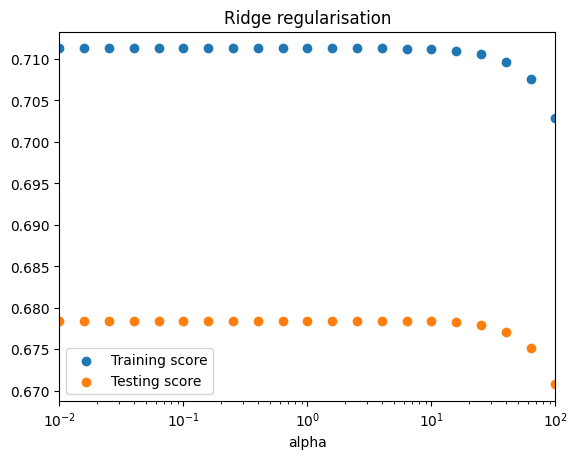

In [25]:
# create an array of 21 alpha values logarithmically distributed between 10**(-2) and 10**2
alfas = np.logspace(-2, 2, num=21)

# create two arrays for storage of the same size as alfas, but filled with zeros
ridge_training_score = np.zeros_like(alfas)
ridge_rsquared = np.zeros_like(alfas)
ridge_score = np.zeros_like(alfas)

# loop over the values in the alfas array, at each loop the current value is alfa
# and idx is incremented by 1, starting at 0
for idx, alfa in enumerate(alfas):
    ridge = Ridge(alpha=alfa, random_state=1235) # instantatiate Ridge regularisation with the current alfa
    ridge.fit(X_train_processed,y_train) # train the model to our data set
# calculate the training score and store in the array ridge_training_score
    ridge_training_score[idx] = ridge.score(X_train_processed, y_train)
    preds_linear = ridge.predict(X_test_processed) # calculate the model prediction for the test data
# calculate the correlation between the predicted and actual test data and store in the  array ridge_rsquared
    ridge_rsquared[idx] = r2_score(y_test, preds_linear)

plt.scatter(alfas, ridge_training_score, label = 'Training score') # plot the training score against alpha
plt.scatter(alfas, ridge_rsquared, label = 'Testing score') # plot the testing score against alpha
plt.xscale('log') # make the x-axis a logarithmic scale
plt.gca().set_xlim(left=.01, right=100); # fix the x-axis limits
plt.title('Ridge regularisation')
plt.xlabel('alpha');
plt.legend(loc = 'best');

opt_alfa_pos = np.argmax(ridge_rsquared)
opt_alfa = alfas[opt_alfa_pos]
print(f'Optimal alpha is {opt_alfa:.3f}')
print(f'Training score with optimal alpha is {ridge_training_score[opt_alfa_pos]:.3f}')
print(f'Testing score with optimal alpha is {ridge_rsquared[opt_alfa_pos]:.3f}')

##Lasso regularisation

In [26]:
# create two arrays for storage of the same size as alfas, but filled with zeros
lasso_training_score = np.zeros_like(alfas)
lasso_rsquared = np.zeros_like(alfas)

# loop over the values in the alfas array, at each loop the current value is alfa
# and idx is incremented by 1, starting at 0
for idx, alfa in enumerate(alfas):
    lasso = Lasso(alpha=alfa) # instantatiate Lasso regularisation with the current alfa
    lasso.fit(X_train_processed,y_train) # train the model to our data set
# calculate the training score and store in the array lasso_training_score
    lasso_training_score[idx] = lasso.score(X_train_processed,y_train)
    preds_linear = lasso.predict(X_test_processed) # calculate the model prediction for the test data
# calculate the correlation between the predicted and actual test data and store in the  array lasso_rsquared
    lasso_rsquared[idx] = r2_score(y_test,preds_linear)

plt.scatter(alfas, lasso_training_score, label = 'Training score') # plot the training score against alpha
plt.scatter(alfas, lasso_rsquared, label = 'Testing score') # plot the testing score against alpha
plt.xscale('log') # make the x-axis a logarithmic scale
plt.gca().set_xlim(left = .01, right = 100); # fix the x-axis limits
plt.title('Lasso regularisation')
plt.xlabel('alpha');
plt.legend(loc='best');

opt_alfa_pos = np.argmax(lasso_rsquared)
opt_alfa = alfas[opt_alfa_pos]
print(f'Optimal alpha is {opt_alfa:.3f}')
print(f'Training score with optimal alpha is {lasso_training_score[opt_alfa_pos]:.3f}')
print(f'Testing score with optimal alpha is {lasso_rsquared[opt_alfa_pos]:.3f}')

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.082e+11, tolerance: 1.746e+08
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.947e+11, tolerance: 1.746e+08
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.916e+11, tolerance: 1.746e

KeyboardInterrupt: 

##Random Forest

In [27]:
from sklearn.ensemble import RandomForestRegressor

In [28]:
rfr_val = RandomForestRegressor(
    n_estimators=128,
    criterion='squared_error',
    max_depth=20,
    min_samples_split=10,
    min_samples_leaf=1,
    min_weight_fraction_leaf=0.0,
    max_features=1.0,
    max_leaf_nodes=None,
    min_impurity_decrease=0.0,
    bootstrap=True,
    oob_score=False,
    n_jobs=4,
    random_state=35,
    verbose=0,
    warm_start=False
)

model_RF_test = rfr_val.fit(X_train_processed, y_train)

In [29]:
yhat = model_RF_test.predict(X_test_processed)

In [30]:
mse = root_mean_squared_error(y_test, yhat)
r2 = r2_score(y_test, yhat)
def rmspe(y_true, y_pred):
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    mask = y_true != 0
    return np.sqrt(np.mean(((y_true[mask] - y_pred[mask]) / y_true[mask]) ** 2))

rmspe_score = rmspe(y_test, yhat)

print(f"MSE: {mse:.2f}")
print(f"R-squared: {r2:.4f}")
print(f"RMSPE: {rmspe_score:.4f}")

MSE: 2152.16
R-squared: 0.6675
RMSPE: 0.2293


In [31]:
importances = pd.Series(rf.feature_importances_, index=features).sort_values(ascending=False)
print(importances)

importances.plot(kind='barh', figsize=(8, 6))
plt.title('Feature Importance')
plt.xlabel('Importance')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

NameError: name 'rf' is not defined

##MLP_1

In [ ]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
continuous_cols = ['DayOfWeek_sin',
    'DayOfWeek_cos',
    'Month_sin',
    'Month_cos',
    'Open',
    'Promo',
    'StateHoliday',
    'SchoolHoliday',
    'StoreType',
    'Assortment',
    'CompetitionDistance',
    'CompetitionOpenSinceMonth',
    'CompetitionOpenSinceYear',
    'Promo2',
    'Promo2SinceWeek',
    'Promo2SinceYear',
    'Year',
    'Month',
    'Day',
    'WeekOfYear',
    'IsPromo2Active']
X_train[continuous_cols] = sc.fit_transform(X_train[continuous_cols])
X_test[continuous_cols] = sc.transform(X_test[continuous_cols])

In [1]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

In [ ]:
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
mlp = MLPRegressor(
 hidden_layer_sizes= (20,20),
 activation = 'relu',
 solver = 'adam',
 max_iter = 5000,
 random_state = 0
)
mlp.fit(X_train, Y_train)

MLPRegressor(hidden_layer_sizes=(20, 20), max_iter=5000, random_state=0)

In [ ]:
Y_pred_test = mlp.predict(X_test)
Y_pred_train = mlp.predict(X_train)

In [ ]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

In [ ]:
# 2. Evaluate Training Set Metrics
train_mae = mean_absolute_error(Y_train, Y_pred_train)
train_rmse = root_mean_squared_error(Y_train, Y_pred_train)
train_r2 = r2_score(Y_train, Y_pred_train)


# 3. Evaluate Testing Set Metrics
test_mae = mean_absolute_error(Y_test, Y_pred_test)
test_rmse = root_mean_squared_error(Y_test, Y_pred_test)
test_r2 = r2_score(Y_test, Y_pred_test)

In [ ]:
print("--- Training Metrics ---")
print(f"MAE : {train_mae}")
print(f"RMSE: {train_rmse}")
print(f"R2  : {train_r2}\n")

print("--- Testing Metrics ---")
print(f"MAE : {test_mae}")
print(f"RMSE: {test_rmse}")
print(f"R2  : {test_r2}")

--- Training Metrics ---
MAE : 1568.5906456904104
RMSE: 2237.461863932214
R2  : 0.6271601476089428

--- Testing Metrics ---
MAE : 1582.4815081868778
RMSE: 2260.0424286648563
R2  : 0.6265645130717491


In [ ]:
mlp = MLPRegressor(
 hidden_layer_sizes= (20,20,20),
 activation = 'relu',
 solver = 'adam',
 max_iter = 5000,
 random_state = 0
)
mlp.fit(X_train, Y_train)
Y_pred_test = mlp.predict(X_test)
Y_pred_train = mlp.predict(X_train)
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

# 2. Evaluate Training Set Metrics
train_mae = mean_absolute_error(Y_train, Y_pred_train)
train_rmse = root_mean_squared_error(Y_train, Y_pred_train)
train_r2 = r2_score(Y_train, Y_pred_train)


# 3. Evaluate Testing Set Metrics
test_mae = mean_absolute_error(Y_test, Y_pred_test)
test_rmse = root_mean_squared_error(Y_test, Y_pred_test)
test_r2 = r2_score(Y_test, Y_pred_test)

print("--- Training Metrics ---")
print(f"MAE : {train_mae}")
print(f"RMSE: {train_rmse}")
print(f"R2  : {train_r2}\n")

print("--- Testing Metrics ---")
print(f"MAE : {test_mae}")
print(f"RMSE: {test_rmse}")
print(f"R2  : {test_r2}")


--- Training Metrics ---
MAE : 1828.116696602408
RMSE: 2579.939093497612
R2  : 0.5042874084201596

--- Testing Metrics ---
MAE : 1849.5777997147657
RMSE: 2607.294931273271
R2  : 0.5029927525736497
